# Réplica de Liu et al. (2025): ML interpretable para el riesgo de sepsis en el triage

**Autor:** Leandro Aaron Caramantin Cruz · Propuesta de Investigación · Ingeniería de Sistemas, Universidad de Lima (2026-2)

**Artículo replicado:** Liu, Z., Shu, W., Li, T., Zhang, X., & Chong, W. (2025). *Interpretable machine learning for predicting sepsis risk in emergency triage patients*. Scientific Reports, 15, 887. https://doi.org/10.1038/s41598-025-85121-z

Este cuaderno sigue el workflow de 6 etapas:

1. Obtención del dataset
2. Preprocesamiento (Modelo 1 y Modelo 2)
3. Desbalance y partición
4. Modelado (8 algoritmos)
5. Evaluación y comparación con el artículo
6. Explicabilidad con SHAP y LIME

Luego viene la **variación propia**: la prueba con la prevalencia real, el balanceo solo en entrenamiento y XGBoost.

> Para ejecutarlo en Colab: **Entorno de ejecución → Ejecutar todas**. Tarda unos 10 minutos.

## 0. Instalación de librerías

In [ ]:
!pip install -q imbalanced-learn xgboost shap lime openpyxl

In [2]:
import time, urllib.request, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, confusion_matrix, brier_score_loss, precision_recall_curve
from xgboost import XGBClassifier
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.3f}'.format)
SEED = 42

## 1. Obtención del dataset

Se usa el dataset que los autores publicaron en figshare (licencia CC BY 4.0), derivado de **MIMIC-IV-ED** (Beth Israel Deaconess Medical Center, Boston). Cada fila es una atención de emergencia de un adulto, y `sepsis` es la variable a predecir (1 = sepsis, según Sepsis-3).

In [3]:
DATA = Path('data_xlsx.xlsx')
if not DATA.exists():
    urllib.request.urlretrieve('https://ndownloader.figshare.com/files/47382490', DATA)  # ~74 MB
df = pd.read_excel(DATA, engine='openpyxl')
print(f'{df.shape[0]:,} atenciones · {df.shape[1]} columnas')
print(f"Sepsis: {df.sepsis.sum():,} ({df.sepsis.mean():.2%}) · Sin sepsis: {(df.sepsis==0).sum():,}")

189,167 atenciones · 99 columnas
Sepsis: 10,824 (5.72%) · Sin sepsis: 178,343


**Nota:** el artículo dice 189,617 pacientes y 5.95% de sepsis, pero sus propios grupos (178,343 + 10,824) suman **189,167**, que es lo que trae el dataset. La prevalencia real es **5.72%**.

## 2. Preprocesamiento: variables de cada modelo

Los datos ya vienen limpios: los autores eliminaron los faltantes y los valores extremos.

- **Modelo 1:** solo los 7 signos vitales del triage, como en el código suplementario.
- **Modelo 2:** signos vitales, edad, sexo, antecedentes y síntomas del motivo de consulta.

Se excluyen los identificadores, las variables duplicadas y las que se conocen **después** del triage (UCI, shock séptico, mortalidad, fechas). Si se incluyeran, habría **fuga de información**.

In [4]:
VITALS = ['temperature','heartrate','resprate','o2sat','sbp','dbp','pain']
IDS = ['subject_id','hadm_id','stay_id']
LEAKAGE = ['sepsis','sepsis_hos','septic_shock','icu','icu_los','morta_28','hospital_expire_flag',
           'sur_time','admittime2','dischtime2','deathtime2','ed_intime2']
DERIVED = ['fahrenheit','MAP','MAP_range','temperature_range','temperature6','non_suspected_infection']
M2 = [c for c in df.columns if c not in IDS + LEAKAGE + DERIVED]
print('Modelo 1:', len(VITALS), 'variables')
print('Modelo 2:', len(M2), 'variables')
print(M2)

Modelo 1: 7 variables
Modelo 2: 78 variables
['suspected_infection', 'temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'age', 'male', 'smoke', 'COPD', 'CKD', 'tumor', 'hypertension', 'CHD', 'CHF', 'diabetes', 'cirrhosis', 'fever', 'fever_prehospital', 'chills', 'tachycardia', 'weakness', 'anemia', 'diarrhea', 'dizziness', 'dyspnea', 'headache', 'fatigue', 'BP_low', 'BP_high', 'BP_low_prehospital', 'BP_high_prehospital', 'lethargy', 'jaundice', 'syncope', 'abscess', 'mantal_altered', 'swelling', 'anxiety', 'palpitations', 'hemoptysis', 'aphasia', 'numbness', 'edema', 'hematuria', 'N_V', 'bradycardia', 'cough', 'confusion', 'slurred', 'sore_throat', 'dysuria', 'cellulitis', 'hyperglycemia', 'hypoglycemia', 'seizure', 'hematemesis', 'rash', 'GIB', 'stroke', 'slurred_speech', 'gait_unsteady', 'visual_changes', 'wound', 'lightheaded', 'fall', 'chest_pain', 'abdominal_pain', 'back_pain', 'leg_pain', 'flank_pain', 'arm_pain', 'arthralgia_pain', 'buttock_pain', 'limb_pain', 'pain'

In [5]:
# ¿Qué pasa si NO se excluyen las columnas con fuga? (demostración)
leaky = [c for c in df.columns if c not in IDS + ['sepsis','icu','icu_los','admittime2','dischtime2','deathtime2','ed_intime2','sur_time']]
X, y = RandomUnderSampler(random_state=SEED).fit_resample(df[leaky], df.sepsis)
Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=SEED)
gb = GradientBoostingClassifier(n_estimators=100, random_state=SEED).fit(Xa, ya)
print(f'AUC con columnas de fuga: {roc_auc_score(yb, gb.predict_proba(Xb)[:,1]):.3f}  <- irreal, por eso se excluyen')

AUC con columnas de fuga: 0.990  <- irreal, por eso se excluyen


## 3-5. Réplica fiel: desbalance, partición, modelado y evaluación

Este es el protocolo del código de los autores:

1. **Submuestreo aleatorio** (RandomUnderSampler) sobre **todo** el dataset, que queda 50% sepsis y 50% no sepsis.
2. División **80/20** aleatoria.
3. Estandarización con StandardScaler.
4. Los **8 algoritmos** con los mismos parámetros, umbral 0.5.

In [6]:
def metrics(y_true, prob, thr=0.5):
    pred = (np.asarray(prob) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    return {'AUC': roc_auc_score(y_true, prob), 'AUPRC': average_precision_score(y_true, prob),
            'F1': f1_score(y_true, pred), 'Accuracy': (tp+tn)/(tp+tn+fp+fn),
            'Sensibilidad': tp/(tp+fn), 'Especificidad': tn/(tn+fp), 'Precision': tp/(tp+fp) if tp+fp else 0,
            'Brier': brier_score_loss(y_true, prob), 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}

def liu_models():
    return {'Logistic Regression': LogisticRegression(random_state=SEED, max_iter=1000),
            'Decision Tree': DecisionTreeClassifier(random_state=SEED),
            'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
            'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=SEED),
            'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
            'KNN': KNeighborsClassifier(n_neighbors=5),
            'SVM': SVC(probability=True, random_state=SEED),
            'Naive Bayes': GaussianNB()}

def replicar(features, nombre):
    X, y = RandomUnderSampler(random_state=SEED).fit_resample(df[features], df.sepsis)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
    sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    rows = []
    for name, m in liu_models().items():
        m.fit(Xtr, ytr)
        rows.append({'Modelo': nombre, 'Algoritmo': name, **metrics(yte, m.predict_proba(Xte)[:,1])})
    print(f'{nombre}: entrenamiento={len(ytr):,} · prueba={len(yte):,} (balanceada 50/50)')
    return pd.DataFrame(rows)

rep = pd.concat([replicar(VITALS, 'Modelo 1'), replicar(M2, 'Modelo 2')], ignore_index=True)

Modelo 1: entrenamiento=17,318 · prueba=4,330 (balanceada 50/50)


Modelo 2: entrenamiento=17,318 · prueba=4,330 (balanceada 50/50)


In [7]:
LIU_AUC = {'Modelo 1': {'Gradient Boosting':.76,'SVM':.75,'Random Forest':.74,'Naive Bayes':.74,'Extra Trees':.73,
                        'Logistic Regression':.72,'KNN':.68,'Decision Tree':.60},
           'Modelo 2': {'Gradient Boosting':.83,'Extra Trees':.82,'Random Forest':.82,'SVM':.82,
                        'Logistic Regression':.79,'KNN':.76,'Naive Bayes':.74,'Decision Tree':.65}}
LIU_F1_M2 = {'Gradient Boosting':.75,'Extra Trees':.74,'Random Forest':.74,'SVM':.74,'Logistic Regression':.72,
             'KNN':.68,'Naive Bayes':.71,'Decision Tree':.64}
rep['AUC Liu'] = [LIU_AUC[m][a] for m, a in zip(rep.Modelo, rep.Algoritmo)]
rep['Diferencia AUC'] = rep['AUC'] - rep['AUC Liu']
rep['F1 Liu'] = [LIU_F1_M2[a] if m == 'Modelo 2' else np.nan for m, a in zip(rep.Modelo, rep.Algoritmo)]
rep[['Modelo','Algoritmo','AUC Liu','AUC','Diferencia AUC','F1 Liu','F1','Sensibilidad','Especificidad','Brier']]

,Modelo,Algoritmo,AUC Liu,AUC,Diferencia AUC,F1 Liu,F1,Sensibilidad,Especificidad,Brier
0,Modelo 1,Logistic Regression,0.720,0.720,-0.000,NaN,0.655,0.635,0.699,0.213
1,Modelo 1,Decision Tree,0.600,0.607,0.007,NaN,0.607,0.609,0.606,0.393
2,Modelo 1,Extra Trees,0.730,0.736,0.006,NaN,0.674,0.664,0.695,0.208
3,Modelo 1,Gradient Boosting,0.760,0.756,-0.004,NaN,0.685,0.650,0.754,0.199
4,Modelo 1,Random Forest,0.740,0.738,-0.002,NaN,0.678,0.674,0.689,0.208
5,Modelo 1,KNN,0.680,0.685,0.005,NaN,0.624,0.600,0.679,0.240
6,Modelo 1,SVM,0.750,0.755,0.005,NaN,0.680,0.656,0.728,0.201
7,Modelo 1,Naive Bayes,0.740,0.741,0.001,NaN,0.603,0.496,0.852,0.225
8,Modelo 2,Logistic Regression,0.790,0.794,0.004,0.720,0.722,0.717,0.734,0.185
9,Modelo 2,Decision Tree,0.650,0.639,-0.011,0.640,0.634,0.629,0.649,0.361


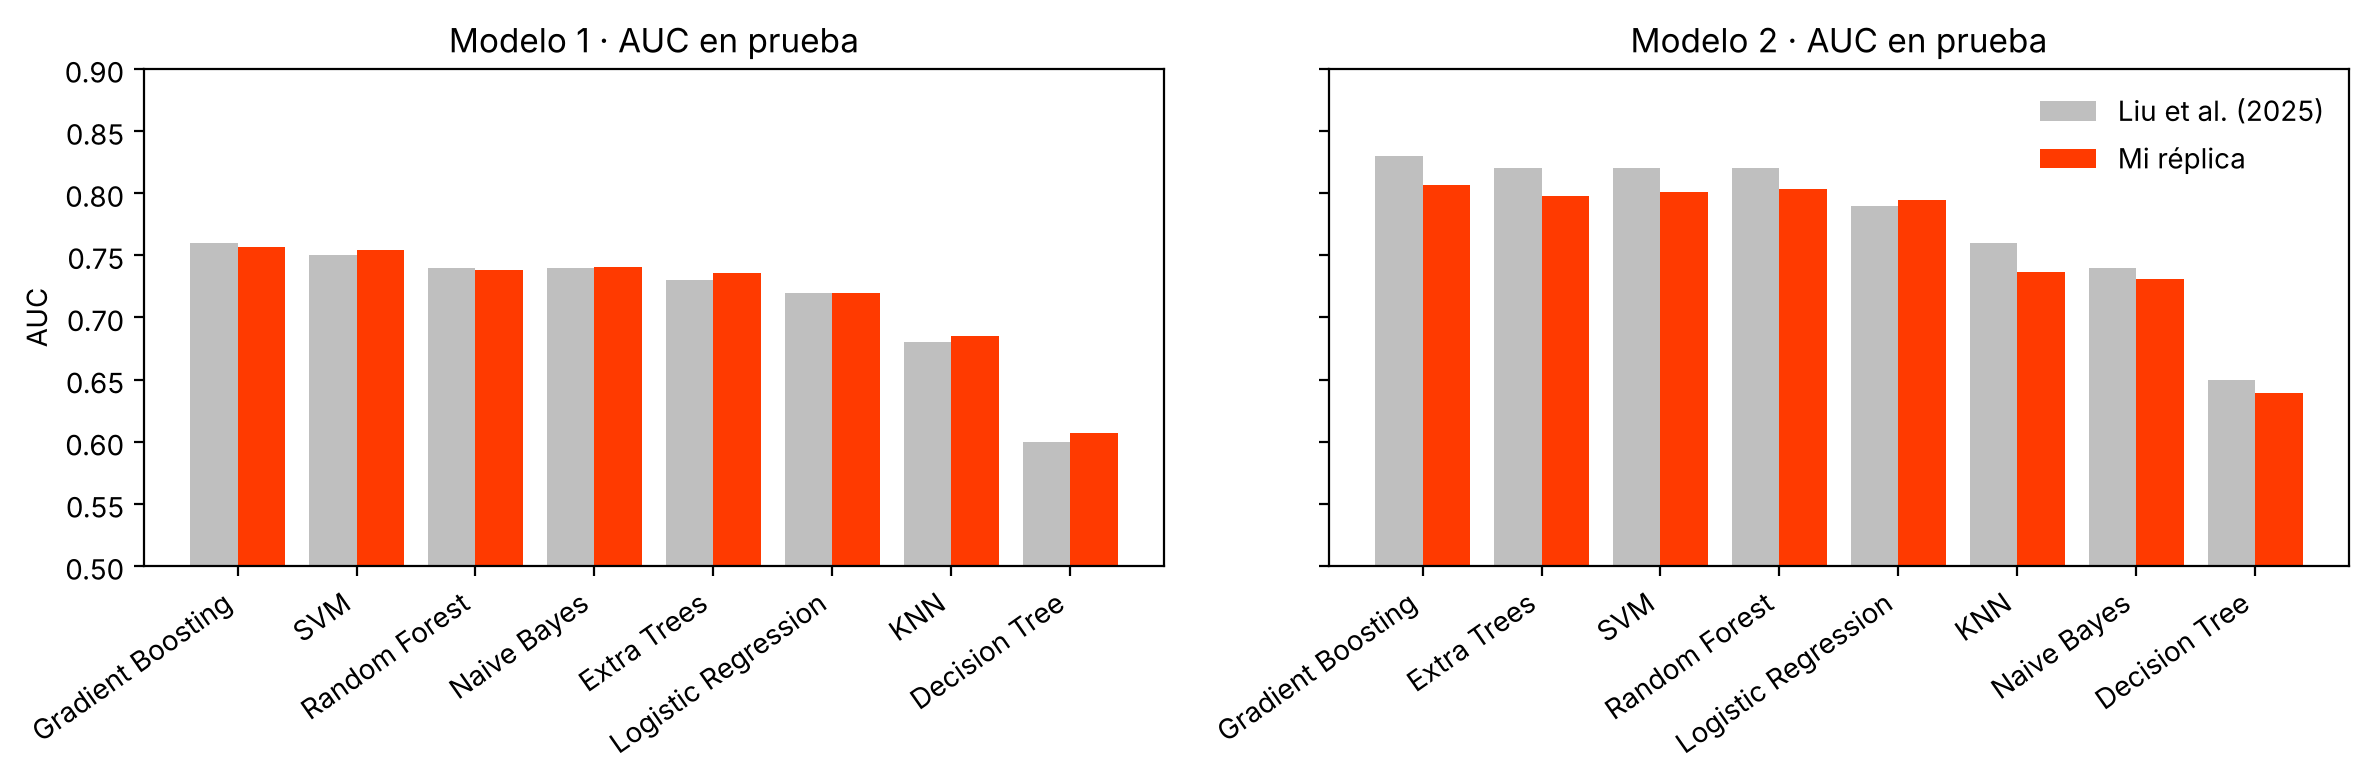

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, m in zip(axes, ['Modelo 1','Modelo 2']):
    d = rep[rep.Modelo == m].sort_values('AUC Liu', ascending=False); x = np.arange(len(d))
    ax.bar(x-.2, d['AUC Liu'], .4, color='#BFBFBF', label='Liu et al. (2025)')
    ax.bar(x+.2, d['AUC'], .4, color='#FF3A00', label='Mi réplica')
    ax.set_xticks(x, d.Algoritmo, rotation=35, ha='right'); ax.set_ylim(.5, .9); ax.set_title(f'{m} · AUC en prueba')
axes[0].set_ylabel('AUC'); axes[1].legend(frameon=False); plt.tight_layout(); plt.show()

**Lectura:**

- **Modelo 1:** los 8 algoritmos quedan a menos de 0.01 de lo publicado.
- **Modelo 2:** quedan entre 0.01 y 0.02 por debajo. El artículo no publica la lista exacta de columnas que usó, y aquí se excluyó todo lo que tiene fuga.

## Variación propia: prueba con la prevalencia real

El artículo submuestrea **antes** de dividir, así que su prueba tiene 50% de sepsis. En una emergencia real, la sepsis es el 5.7%. Mi variación cambia cuatro cosas:

1. Divide **primero**, de forma estratificada: 70% entrenamiento, 15% validación y 15% prueba. La prueba conserva el 5.7%.
2. Balancea **solo el entrenamiento**: sin balanceo, con submuestreo o con SMOTE.
3. Agrega **XGBoost**.
4. Elige el **umbral** en validación, maximizando el F1.

In [9]:
X, y = df[M2], df.sepsis
Xtr, Xtmp, ytr, ytmp = train_test_split(X, y, test_size=.30, stratify=y, random_state=SEED)
Xva, Xte, yva, yte = train_test_split(Xtmp, ytmp, test_size=.50, stratify=ytmp, random_state=SEED)
sc = StandardScaler().fit(Xtr); Xtr_s, Xva_s, Xte_s = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)
print(f'Entrenamiento={len(ytr):,} · Validación={len(yva):,} · Prueba={len(yte):,} · sepsis en prueba={yte.mean():.2%}')

def var_models():
    return {'Logistic Regression': LogisticRegression(random_state=SEED, max_iter=1000),
            'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
            'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=SEED),
            'XGBoost': XGBClassifier(n_estimators=300, learning_rate=.05, max_depth=5, subsample=.8,
                                     colsample_bytree=.8, eval_metric='logloss', random_state=SEED, n_jobs=-1)}

def best_thr(yv, pv):
    p, r, t = precision_recall_curve(yv, pv); f = 2*p*r/np.clip(p+r, 1e-9, None)
    return float(t[np.nanargmax(f[:-1])])

rows = []
for s_name, sampler in {'Sin balanceo': None, 'Submuestreo': RandomUnderSampler(random_state=SEED),
                        'SMOTE': SMOTE(random_state=SEED)}.items():
    Xb, yb = (Xtr_s, ytr) if sampler is None else sampler.fit_resample(Xtr_s, ytr)
    for name, m in var_models().items():
        m.fit(Xb, yb); pv, pt = m.predict_proba(Xva_s)[:,1], m.predict_proba(Xte_s)[:,1]
        t = best_thr(yva, pv)
        rows.append({'Balanceo': s_name, 'Algoritmo': name, 'Umbral': '0.5', **metrics(yte, pt, .5)})
        rows.append({'Balanceo': s_name, 'Algoritmo': name, 'Umbral': f'validación ({t:.2f})', **metrics(yte, pt, t)})
var = pd.DataFrame(rows)
var[var.Umbral != '0.5'][['Balanceo','Algoritmo','Umbral','AUC','AUPRC','Sensibilidad','Precision','F1']]

Entrenamiento=132,416 · Validación=28,375 · Prueba=28,376 · sepsis en prueba=5.72%


,Balanceo,Algoritmo,Umbral,AUC,AUPRC,Sensibilidad,Precision,F1
1,Sin balanceo,Logistic Regression,validación (0.14),0.798,0.236,0.386,0.247,0.301
3,Sin balanceo,Random Forest,validación (0.18),0.792,0.246,0.372,0.261,0.307
5,Sin balanceo,Gradient Boosting,validación (0.16),0.811,0.271,0.325,0.305,0.315
7,Sin balanceo,XGBoost,validación (0.15),0.818,0.276,0.397,0.279,0.328
9,Submuestreo,Logistic Regression,validación (0.68),0.796,0.222,0.467,0.213,0.292
11,Submuestreo,Random Forest,validación (0.71),0.809,0.237,0.398,0.241,0.300
13,Submuestreo,Gradient Boosting,validación (0.72),0.810,0.264,0.396,0.271,0.322
15,Submuestreo,XGBoost,validación (0.75),0.815,0.265,0.411,0.268,0.324
17,SMOTE,Logistic Regression,validación (0.72),0.796,0.231,0.421,0.230,0.297
19,SMOTE,Random Forest,validación (0.30),0.790,0.208,0.434,0.215,0.288


### Hallazgo: el mismo modelo, probado con 50% de sepsis o con la prevalencia real

,Prueba 50/50 (Liu),Prueba real 5.7%
AUC,0.807,0.810
Sensibilidad,0.705,0.720
Precision,0.738,0.151
F1,0.721,0.250


Con la prevalencia real: 7,746 alertas de sepsis, de las cuales solo 1,169 eran sepsis (15%).


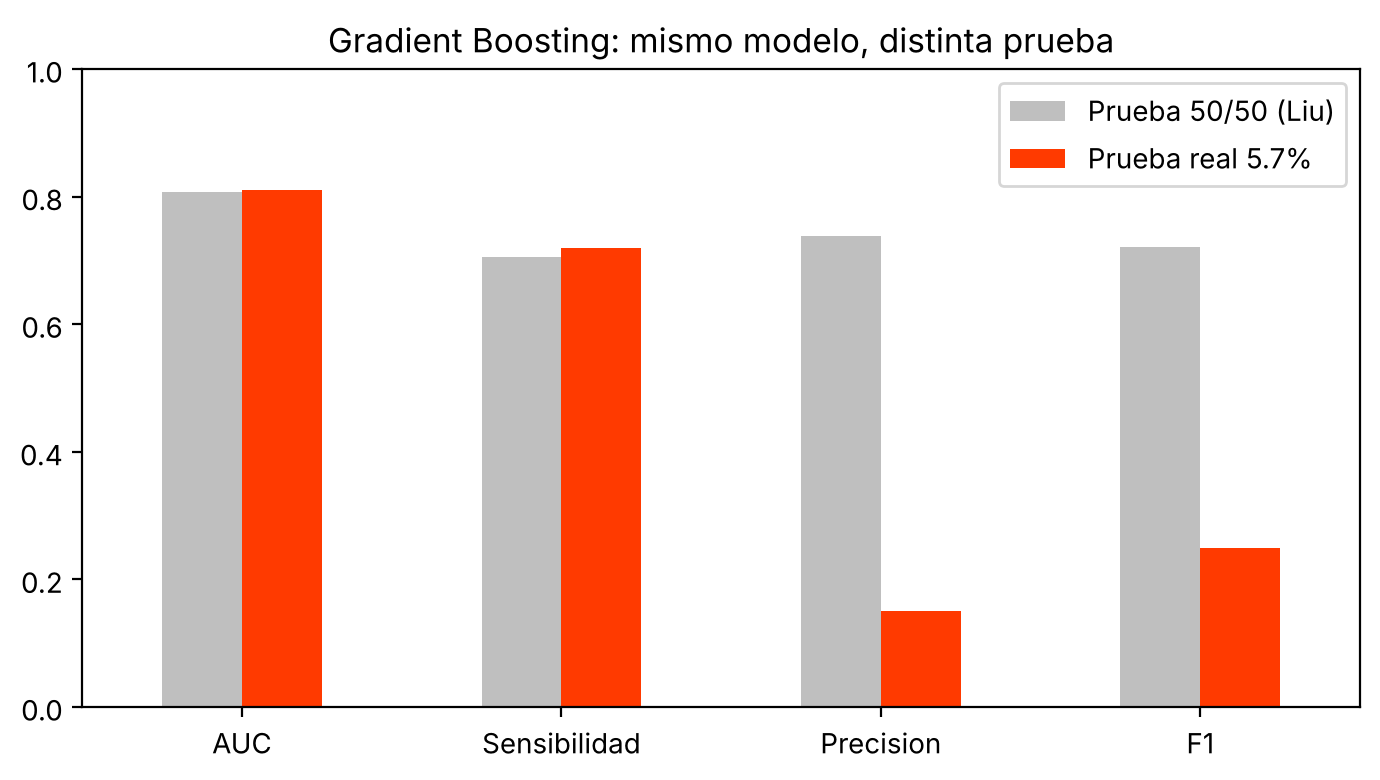

In [10]:
a = rep[(rep.Modelo=='Modelo 2') & (rep.Algoritmo=='Gradient Boosting')].iloc[0]
b = var[(var.Balanceo=='Submuestreo') & (var.Algoritmo=='Gradient Boosting') & (var.Umbral=='0.5')].iloc[0]
comp = pd.DataFrame({'Prueba 50/50 (Liu)': a[['AUC','Sensibilidad','Precision','F1']],
                     'Prueba real 5.7%': b[['AUC','Sensibilidad','Precision','F1']]}).astype(float)
display(comp.round(3))
print(f"Con la prevalencia real: {int(b.TP)+int(b.FP):,} alertas de sepsis, de las cuales solo {int(b.TP):,} eran sepsis "
      f"({int(b.TP)/(int(b.TP)+int(b.FP)):.0%}).")
comp.plot.bar(color=['#BFBFBF','#FF3A00'], figsize=(7,4), rot=0, ylim=(0,1), title='Gradient Boosting: mismo modelo, distinta prueba')
plt.tight_layout(); plt.show()

**Lectura:**

- El AUC y la sensibilidad casi no cambian, pero la precisión y el F1 caen mucho. Con la prevalencia real, la mayoría de alertas serían falsas.
- XGBoost logra el mejor AUC y AUPRC.
- SMOTE no mejora a los modelos de árboles. Elegir el umbral en validación es más efectivo.

## 6. Explicabilidad con SHAP y LIME

Se usa Gradient Boosting con el protocolo de Liu (Modelo 2), igual que en el artículo.

- **SHAP global:** qué variables pesan más en todos los pacientes.
- **SHAP y LIME por paciente:** por qué un paciente concreto recibe su probabilidad.

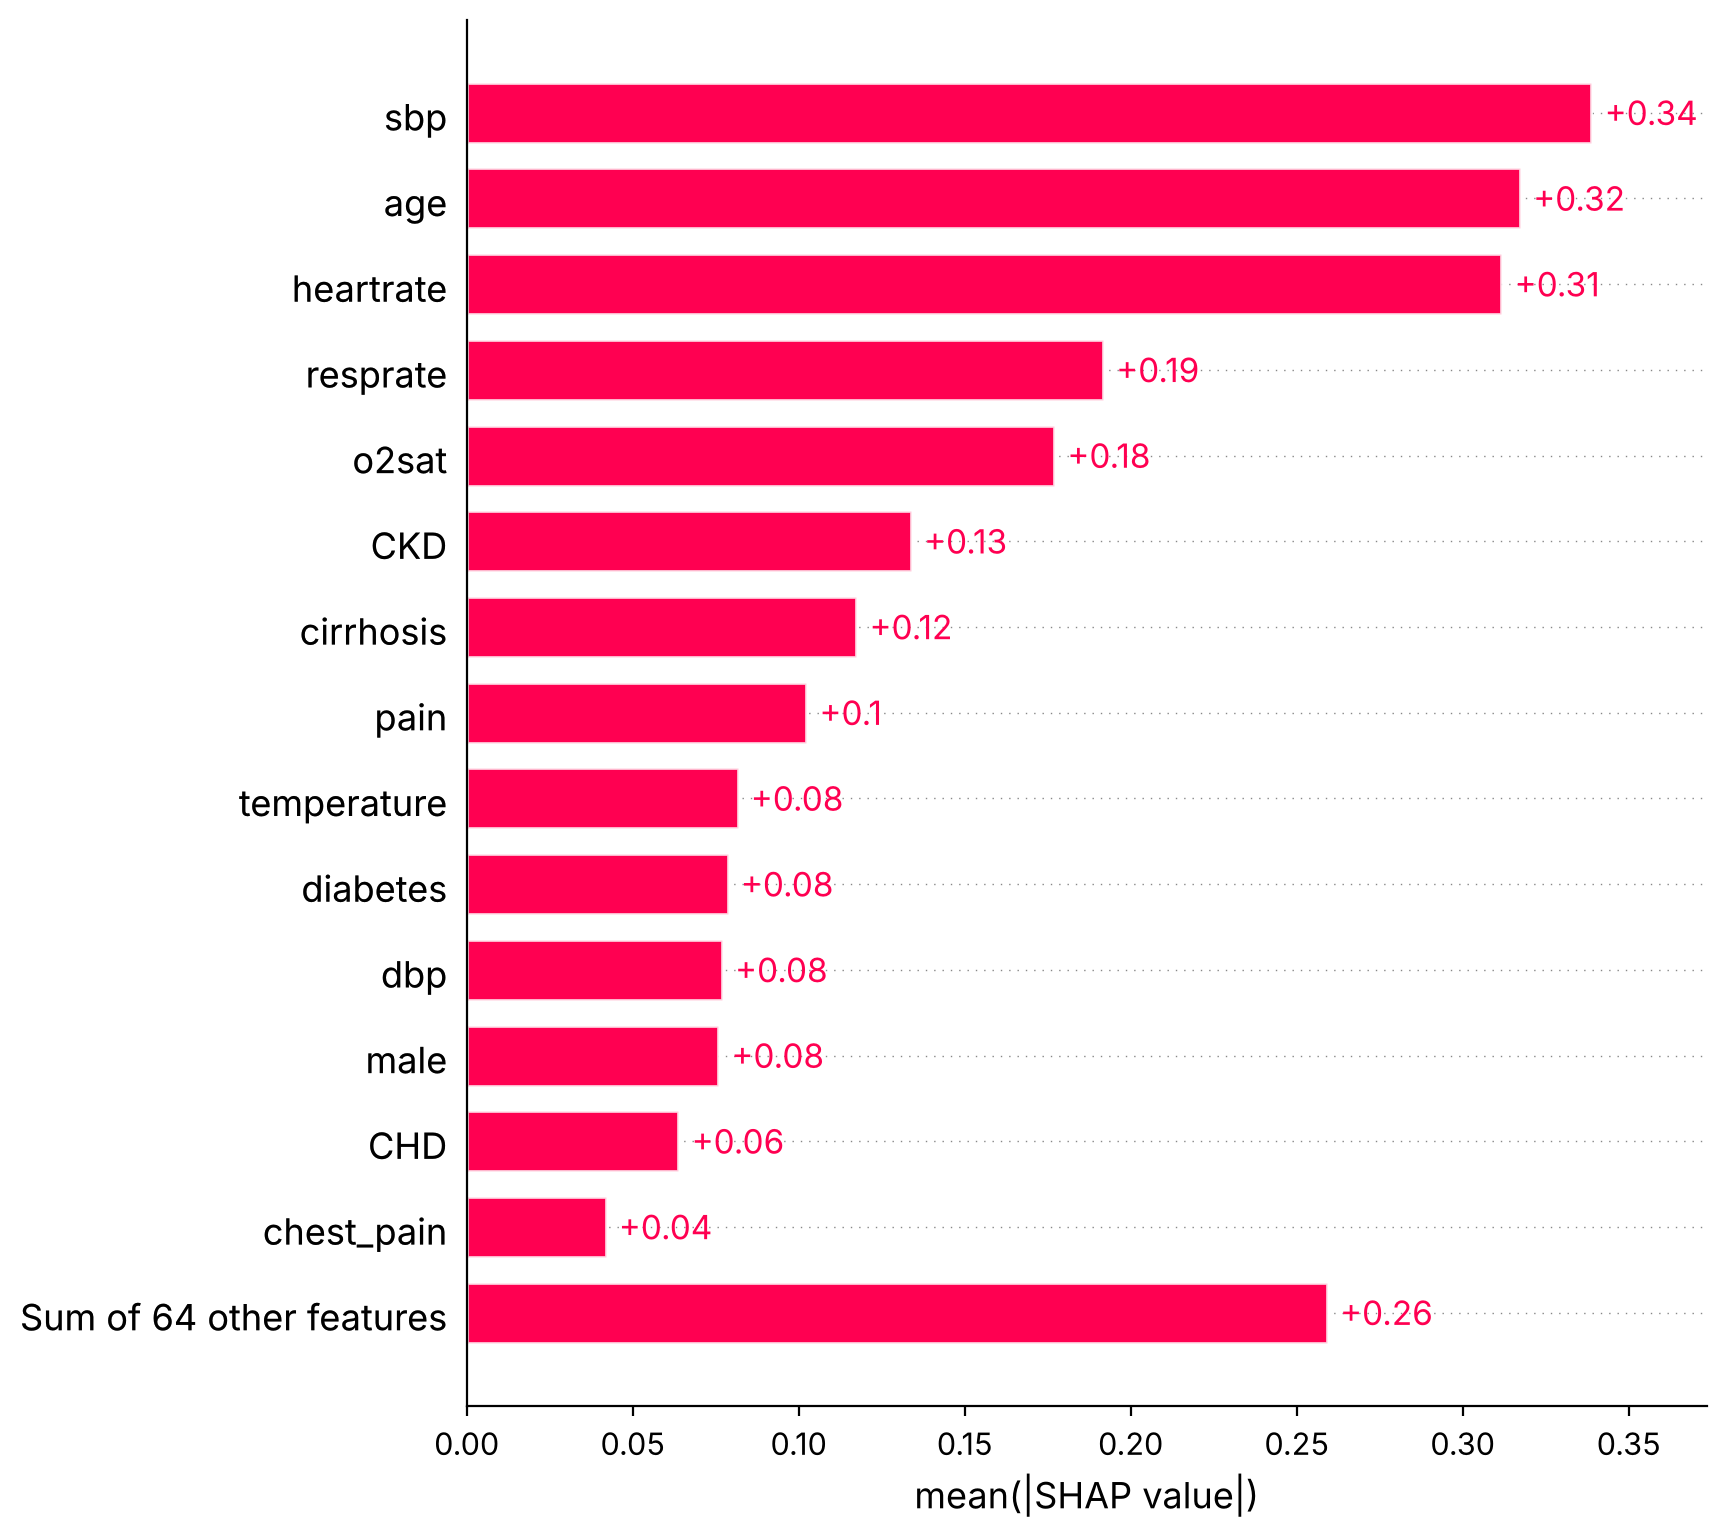

In [11]:
import shap, lime.lime_tabular
X, y = RandomUnderSampler(random_state=SEED).fit_resample(df[M2], df.sepsis)
Xtr2, Xte2, ytr2, yte2 = train_test_split(X, y, test_size=0.2, random_state=SEED)
gb = GradientBoostingClassifier(n_estimators=100, random_state=SEED).fit(Xtr2, ytr2)
sv = shap.TreeExplainer(gb)(Xte2)
shap.plots.bar(sv, max_display=15)

Paciente 7: probabilidad de sepsis 74% · tuvo sepsis = 1


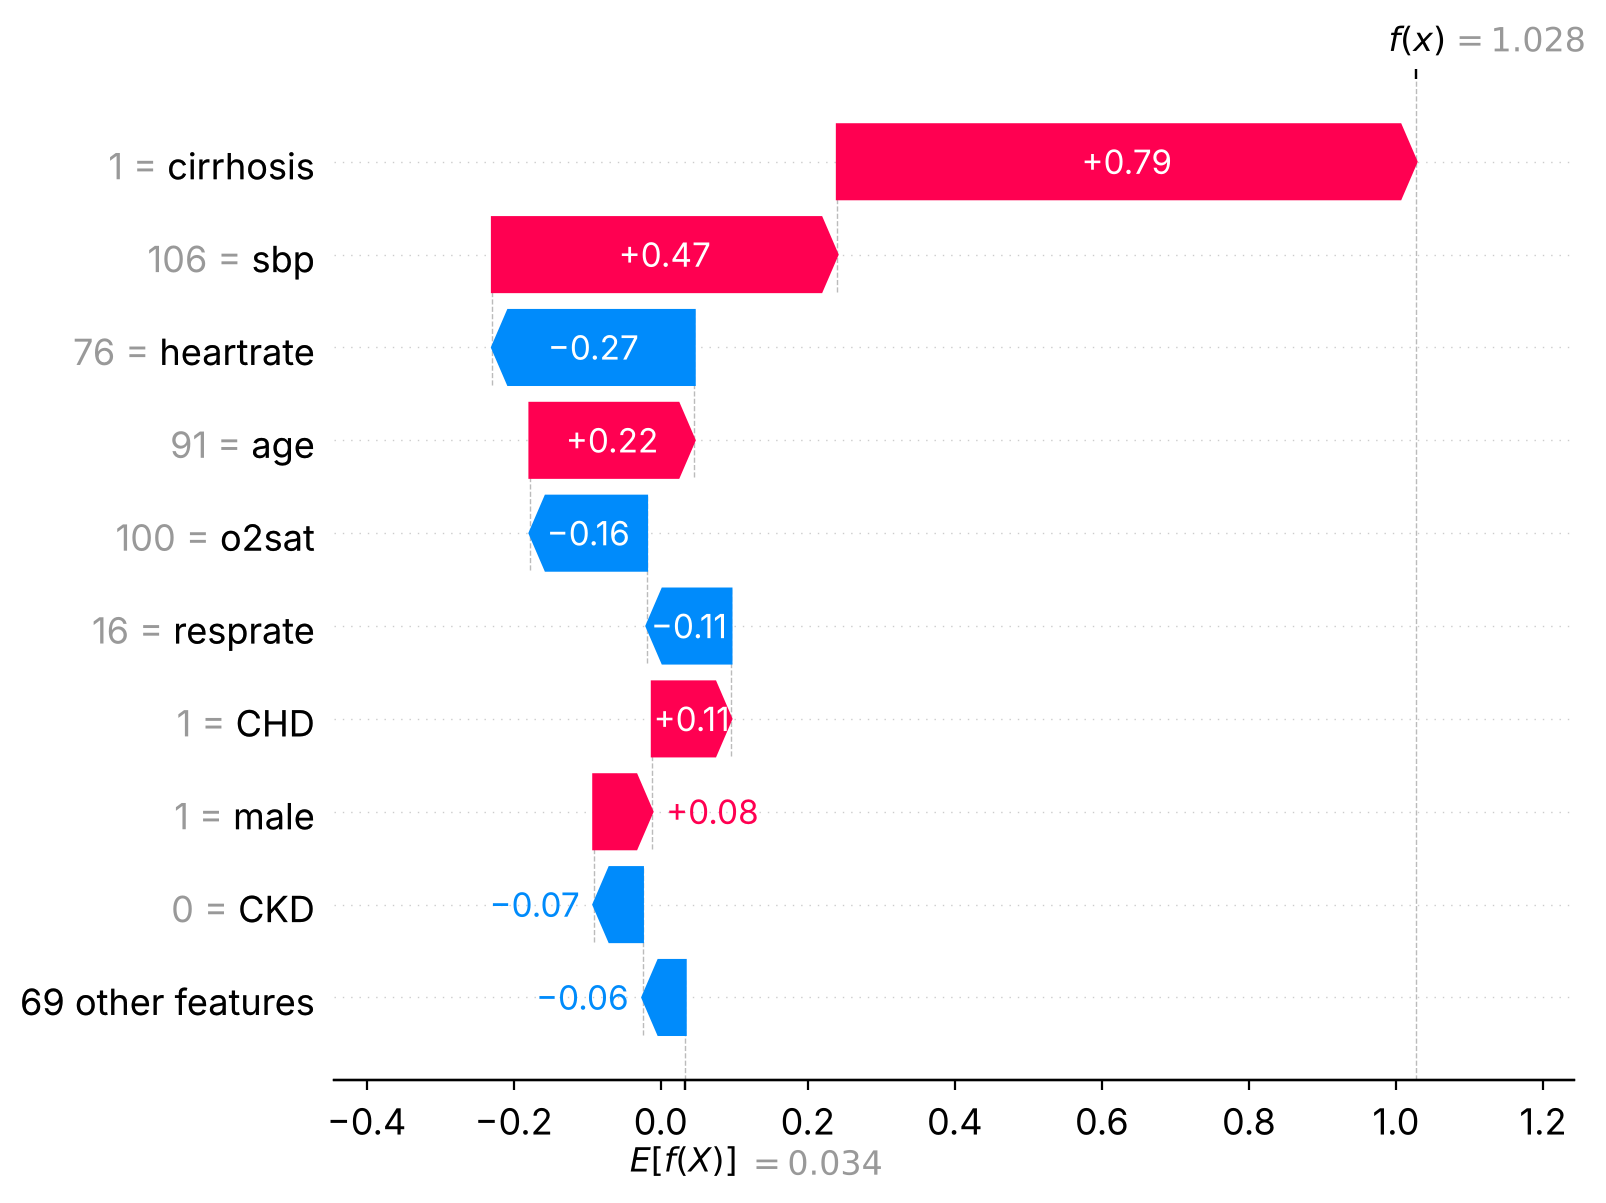

In [12]:
probs = gb.predict_proba(Xte2)[:,1]
i = int(np.where((yte2.values == 1) & (probs > 0.7))[0][0])
print(f'Paciente {i}: probabilidad de sepsis {probs[i]:.0%} · tuvo sepsis = {yte2.values[i]}')
shap.plots.waterfall(sv[i], max_display=10)

In [13]:
exp = lime.lime_tabular.LimeTabularExplainer(Xtr2.values, feature_names=M2, class_names=['No sepsis','Sepsis'],
                                              discretize_continuous=True, random_state=SEED)
e = exp.explain_instance(Xte2.values[i], gb.predict_proba, num_features=10)
pd.DataFrame(e.as_list(), columns=['Condición','Peso (+ sube el riesgo)'])

,Condición,Peso (+ sube el riesgo)
0,cirrhosis > 0.00,0.198
1,sbp <= 112.00,0.183
2,anxiety <= 0.00,0.172
3,BP_high_prehospital <= 0.00,0.151
4,lethargy <= 0.00,-0.130
5,palpitations <= 0.00,0.115
6,CKD <= 0.00,-0.100
7,BP_low <= 0.00,-0.100
8,numbness <= 0.00,0.096
9,mantal_altered <= 0.00,-0.084


**Lectura:** en este paciente, SHAP y LIME coinciden en que la **cirrosis** y la **presión sistólica baja** son lo que más sube el riesgo de sepsis.

## Conclusión

- **La réplica confirma el artículo:** el Modelo 1 sale igual y el Modelo 2 queda muy cerca.
- **Lo que hay que corregir para usarlo en la práctica:** evaluarlo con la **prevalencia real**, porque la precisión cae mucho aunque el AUC se mantenga.
- **Lo que aplicaré en mi tesis:** balancear solo el entrenamiento, elegir el umbral en validación, reportar métricas por clase y explicar cada predicción con SHAP y LIME.